In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from churn_utils import add_tenure_bucket
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    brier_score_loss
)
from sklearn.calibration import CalibrationDisplay
from sklearn.model_selection import cross_val_predict
from sklearn.inspection import permutation_importance

In [2]:
df = pd.read_csv('Wa_Fn-UseC_-Telco-Customer-Churn.csv')
df.head(15)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [3]:
print("Dataset shape:", df.shape)
df.info()

Dataset shape: (7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip(),errors="coerce")

In [5]:
print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False))

Duplicate rows: 0

Missing values:


TotalCharges        11
gender               0
SeniorCitizen        0
Partner              0
customerID           0
Dependents           0
tenure               0
MultipleLines        0
PhoneService         0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
InternetService      0
TechSupport          0
StreamingTV          0
Contract             0
StreamingMovies      0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
Churn                0
dtype: int64

In [6]:
df.loc[
    df["TotalCharges"].isnull(),
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [7]:
mask = df["TotalCharges"].isnull() & (df["tenure"] == 0)
df.loc[mask, "TotalCharges"] = 0

print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())
print("TotalCharges dtype:", df["TotalCharges"].dtype)

Missing TotalCharges: 0
TotalCharges dtype: float64


In [8]:
print(df["Churn"].value_counts())
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [9]:
print("Numerical Columns:")
print(df.select_dtypes(include=["int64", "float64"]).columns.tolist())

print("\nCategorical Columns:")
print(df.select_dtypes(include=["str"]).columns.tolist())

Numerical Columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Columns:
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


In [10]:
categorical_cols = df.select_dtypes(include=["str"]).columns

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts().to_dict())


customerID:
{'7590-VHVEG': 1, '5575-GNVDE': 1, '3668-QPYBK': 1, '7795-CFOCW': 1, '9237-HQITU': 1, '9305-CDSKC': 1, '1452-KIOVK': 1, '6713-OKOMC': 1, '7892-POOKP': 1, '6388-TABGU': 1, '9763-GRSKD': 1, '7469-LKBCI': 1, '8091-TTVAX': 1, '0280-XJGEX': 1, '5129-JLPIS': 1, '3655-SNQYZ': 1, '8191-XWSZG': 1, '9959-WOFKT': 1, '4190-MFLUW': 1, '4183-MYFRB': 1, '8779-QRDMV': 1, '1680-VDCWW': 1, '1066-JKSGK': 1, '3638-WEABW': 1, '6322-HRPFA': 1, '6865-JZNKO': 1, '6467-CHFZW': 1, '8665-UTDHZ': 1, '5248-YGIJN': 1, '8773-HHUOZ': 1, '3841-NFECX': 1, '4929-XIHVW': 1, '6827-IEAUQ': 1, '7310-EGVHZ': 1, '3413-BMNZE': 1, '6234-RAAPL': 1, '6047-YHPVI': 1, '6572-ADKRS': 1, '5380-WJKOV': 1, '8168-UQWWF': 1, '8865-TNMNX': 1, '9489-DEDVP': 1, '9867-JCZSP': 1, '4671-VJLCL': 1, '4080-IIARD': 1, '3714-NTNFO': 1, '5948-UJZLF': 1, '7760-OYPDY': 1, '7639-LIAYI': 1, '2954-PIBKO': 1, '8012-SOUDQ': 1, '9420-LOJKX': 1, '6575-SUVOI': 1, '7495-OOKFY': 1, '4667-QONEA': 1, '1658-BYGOY': 1, '8769-KKTPH': 1, '5067-XJQFU': 1, 

In [11]:
pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


In [12]:
pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


In [13]:
pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


In [14]:
pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

Churn,No,Yes
SeniorCitizen,,
0,76.39,23.61
1,58.32,41.68


In [15]:
pd.crosstab(
    df["Partner"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

Churn,No,Yes
Partner,,
No,67.04,32.96
Yes,80.34,19.66


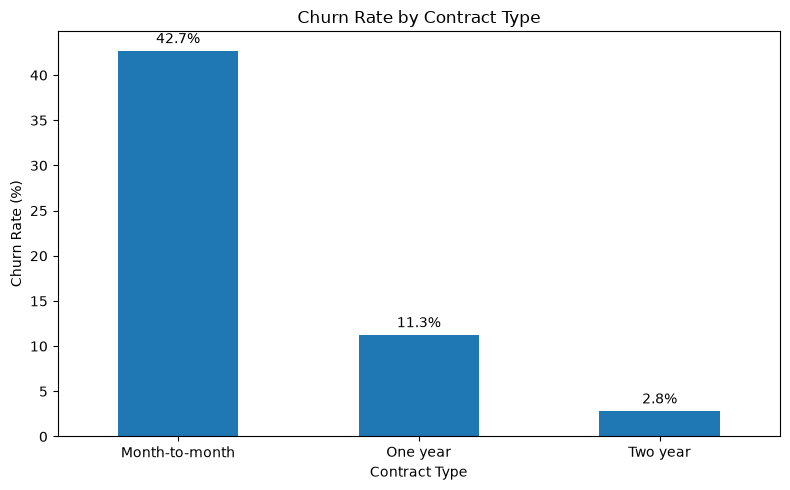

In [16]:
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

churn_rate = df.groupby("Contract")["ChurnFlag"].mean() * 100

ax = churn_rate.plot(kind="bar", figsize=(8, 5))

ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

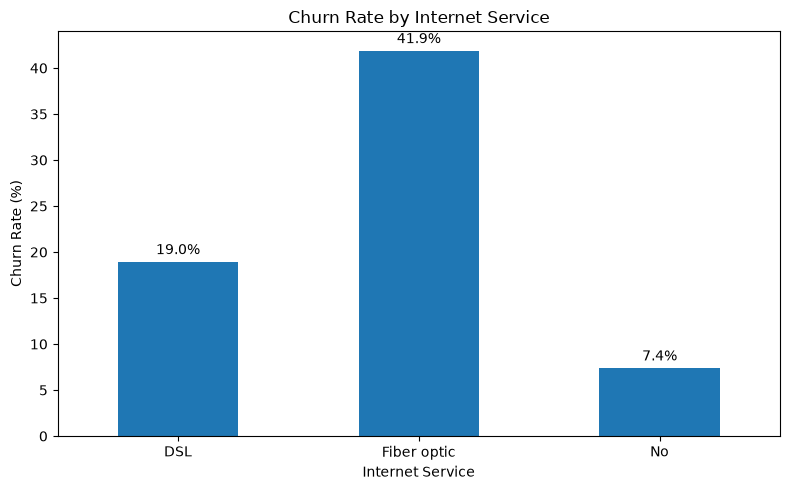

In [17]:
churn_rate = df.groupby("InternetService")["ChurnFlag"].mean() * 100

ax = churn_rate.plot(kind="bar", figsize=(8, 5))

ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

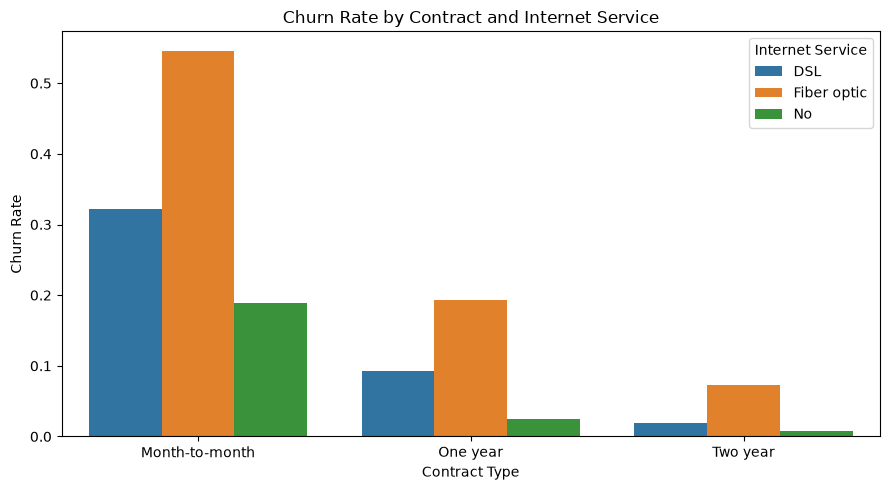

In [18]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Contract",
    y="ChurnFlag",
    hue="InternetService",
    errorbar=None
)

plt.title("Churn Rate by Contract and Internet Service")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate")
plt.legend(title="Internet Service")
plt.tight_layout()
plt.show()

In [19]:
churn_by_dependents = pd.crosstab(
    df["Dependents"],
    df["Churn"],
    normalize="index"
).mul(100).round(2)

churn_by_dependents

Churn,No,Yes
Dependents,,
No,68.72,31.28
Yes,84.55,15.45


In [20]:
df.groupby(
    ["Contract", "Dependents"]
)["ChurnFlag"].mean().mul(100).round(2).unstack()

Dependents,No,Yes
Contract,,
Month-to-month,45.24,32.83
One year,12.42,9.23
Two year,3.31,2.28


In [21]:
df.groupby("Churn")[[
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]].describe().round(2)

tenure                                            MonthlyCharges  \
        count   mean    std  min   25%   50%   75%   max          count   
Churn                                                                     
No     5174.0  37.57  24.11  0.0  15.0  38.0  61.0  72.0         5174.0   
Yes    1869.0  17.98  19.53  1.0   2.0  10.0  29.0  72.0         1869.0   

              ...               TotalCharges                                  \
        mean  ...   75%     max        count     mean      std    min    25%   
Churn         ...                                                              
No     61.27  ...  88.4  118.75       5174.0  2549.91  2329.95   0.00  572.9   
Yes    74.44  ...  94.2  118.35       1869.0  1531.80  1890.82  18.85  134.5   

                                  
           50%      75%      max  
Churn                             
No     1679.52  4262.85  8672.45  
Yes     703.55  2331.30  8684.80  

[2 rows x 24 columns]

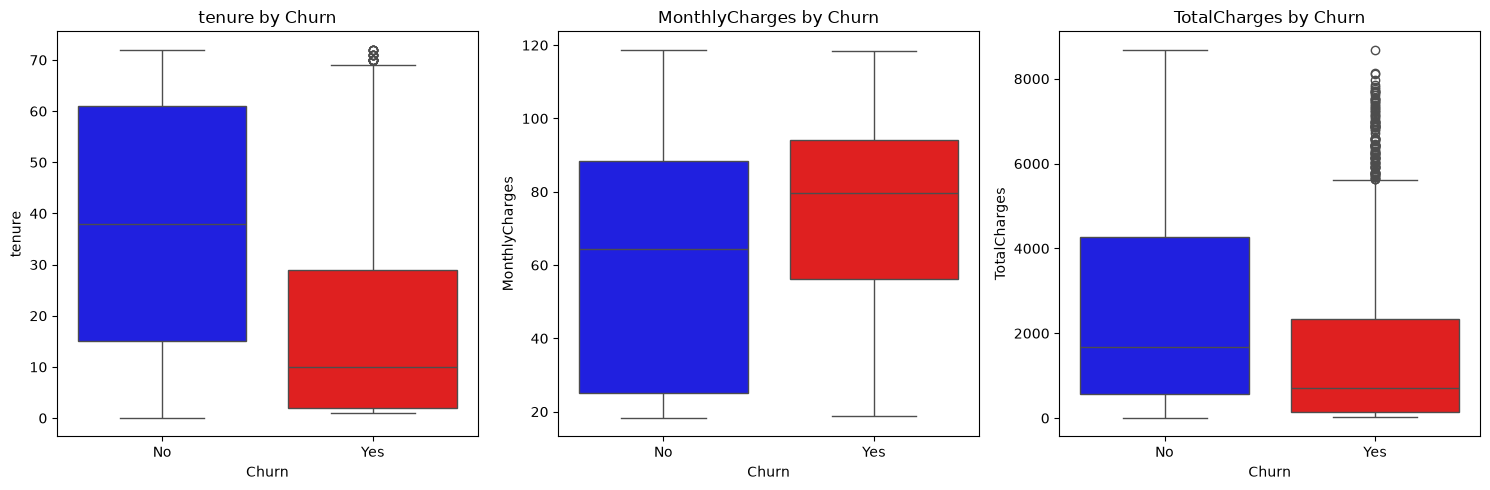

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(
        data=df,
        x="Churn",
        y=col,
        hue="Churn",
        order=["No", "Yes"],
        hue_order=["No", "Yes"],
        palette={"No": "blue", "Yes": "red"},
        legend=False,
        ax=ax
    )
    ax.set_title(f"{col} by Churn")

plt.tight_layout()
plt.show()

## Data Preparation

In [23]:
X = df.drop(columns=["Churn", "customerID", "ChurnFlag"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts(normalize=True).mul(100).round(2))

Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [25]:
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
] + ["TenureBucket"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

feature_engineering = FunctionTransformer(add_tenure_bucket)


def build_pipeline(model):
    return Pipeline([
        ("features", feature_engineering),
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

In [26]:
baseline_model = DummyClassifier(strategy="most_frequent")

baseline_model.fit(X_train, y_train)

y_pred_baseline = baseline_model.predict(X_test)

print(classification_report(
    y_test,
    y_pred_baseline,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

              precision    recall  f1-score   support

    No Churn       0.73      1.00      0.85      1035
       Churn       0.00      0.00      0.00       374

    accuracy                           0.73      1409
   macro avg       0.37      0.50      0.42      1409
weighted avg       0.54      0.73      0.62      1409



In [27]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}


## Model Comparison

In [28]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

results = []

for name, model in models.items():
    pipeline = build_pipeline(model)

    scores = cross_validate(
        pipeline, X_train, y_train,
        cv=cv, scoring=scoring, n_jobs=-1
    )

    results.append({
        "Model": name,
        **{metric: scores[f"test_{metric}"].mean() for metric in scoring}
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("f1", ascending=False)
    .reset_index(drop=True)
)

results_df.round(3)

,Model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.807,0.673,0.534,0.595,0.848
1,Gradient Boosting,0.803,0.661,0.528,0.587,0.847
2,Random Forest,0.787,0.631,0.480,0.545,0.823
3,Decision Tree,0.733,0.497,0.503,0.499,0.660


## Gradient Boosting Tuning

In [29]:
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__learning_rate": [0.03, 0.1],
    "classifier__max_depth": [2, 3],
    "classifier__subsample": [0.8, 1.0]
}

gb_pipeline = build_pipeline(GradientBoostingClassifier(random_state=42))

grid = GridSearchCV(
    gb_pipeline, param_grid,
    scoring="roc_auc", cv=cv, n_jobs=-1
)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV ROC-AUC:", round(grid.best_score_, 4))

Best params: {'classifier__learning_rate': 0.03, 'classifier__max_depth': 3, 'classifier__n_estimators': 200, 'classifier__subsample': 0.8}
Best CV ROC-AUC: 0.8505


In [30]:
best_gb = grid.best_estimator_

y_train_proba_gb = cross_val_predict(
    best_gb, X_train, y_train,
    cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]

In [31]:
customer_value = 500   # value of a retained customer
offer_cost = 50        # cost of one retention offer
success_rate = 0.30    # share of churners saved by the offer


def net_benefit(y_true, proba, threshold):
    flagged = proba >= threshold
    saved = (flagged & (y_true == 1)).sum() * success_rate * customer_value
    spent = flagged.sum() * offer_cost
    return saved - spent


def threshold_table(y_true, proba, thresholds=np.arange(0.05, 0.81, 0.05)):
    y_true = np.asarray(y_true)
    return pd.DataFrame({
        "Threshold": thresholds.round(2),
        "Churn Precision": [precision_score(y_true, proba >= t, zero_division=0) for t in thresholds],
        "Churn Recall": [recall_score(y_true, proba >= t) for t in thresholds],
        "Net Benefit": [net_benefit(y_true, proba, t) for t in thresholds],
    })


gb_cost_df = threshold_table(y_train, y_train_proba_gb)
gb_threshold = gb_cost_df.loc[gb_cost_df["Net Benefit"].idxmax(), "Threshold"]

print("Best GB threshold:", gb_threshold)
gb_cost_df.round(3)

Best GB threshold: 0.35


,Threshold,Churn Precision,Churn Recall,Net Benefit
0,0.05,0.349,0.985,9650.0
1,0.10,0.404,0.941,37050.0
2,0.15,0.449,0.895,51700.0
3,0.20,0.487,0.858,60700.0
4,0.25,0.515,0.809,64100.0
5,0.30,0.546,0.763,66650.0
6,0.35,0.584,0.699,67250.0
7,0.40,0.616,0.642,66100.0
8,0.45,0.647,0.583,63400.0
9,0.50,0.672,0.524,59250.0


In [32]:
y_test_proba_gb = best_gb.predict_proba(X_test)[:, 1]
y_test_arr = y_test.to_numpy()

for t in [gb_threshold, 0.5]:
    print(f"Threshold {t}: net benefit = {net_benefit(y_test_arr, y_test_proba_gb, t):,.0f}")

Threshold 0.35: net benefit = 16,400
Threshold 0.5: net benefit = 14,550


In [33]:
lr_pipeline = build_pipeline(
    LogisticRegression(max_iter=1000, random_state=42)
)

y_train_proba_cv = cross_val_predict(
    lr_pipeline, X_train, y_train,
    cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]

In [34]:
threshold_results = []

thresholds = np.arange(0.20, 0.61, 0.05)

for threshold in thresholds:
    y_pred_threshold = (
        y_train_proba_cv >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Churn Precision": precision_score(
            y_train, y_pred_threshold, zero_division=0
        ),
        "Churn Recall": recall_score(
            y_train, y_pred_threshold, zero_division=0
        ),
        "Churn F1": f1_score(
            y_train, y_pred_threshold, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(3)

,Threshold,Churn Precision,Churn Recall,Churn F1
0,0.20,0.476,0.866,0.614
1,0.25,0.512,0.812,0.628
2,0.30,0.543,0.756,0.632
3,0.35,0.572,0.712,0.634
4,0.40,0.607,0.656,0.631
5,0.45,0.634,0.593,0.613
6,0.50,0.672,0.534,0.595
7,0.55,0.699,0.458,0.553
8,0.60,0.722,0.381,0.498


In [35]:
best_threshold = threshold_df.loc[threshold_df["Churn F1"].idxmax(), "Threshold"]

final_lr_model = build_pipeline(
    LogisticRegression(max_iter=1000, random_state=42)
)

final_lr_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...0023B183C0250>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False


In [36]:
y_test_proba = final_lr_model.predict_proba(X_test)[:, 1]

y_pred_final = (y_test_proba >= best_threshold).astype(int)

print(classification_report(
    y_test,
    y_pred_final,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

print("ROC-AUC:", round(roc_auc_score(y_test, y_test_proba), 3))

              precision    recall  f1-score   support

    No Churn       0.88      0.80      0.84      1035
       Churn       0.56      0.71      0.63       374

    accuracy                           0.78      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.80      0.78      0.78      1409

ROC-AUC: 0.845


In [37]:
final_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Gradient Boosting (tuned)"],
    "ROC-AUC": [
        roc_auc_score(y_test, y_test_proba),
        roc_auc_score(y_test, y_test_proba_gb)
    ],
    "Net Benefit": [
        net_benefit(y_test_arr, y_test_proba, best_threshold),
        net_benefit(y_test_arr, y_test_proba_gb, best_threshold)
    ]
})

final_comparison.round(3)

,Model,ROC-AUC,Net Benefit
0,Logistic Regression,0.845,16100.0
1,Gradient Boosting (tuned),0.846,16400.0


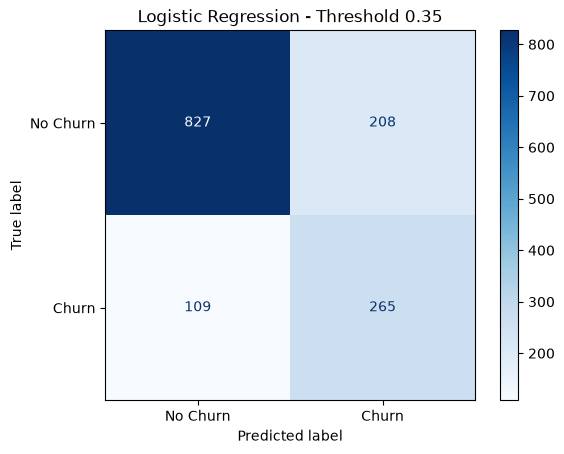

In [38]:
cm = confusion_matrix(y_test, y_pred_final)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Threshold 0.35")
plt.show()

In [39]:
# Get feature names after preprocessing
feature_names = final_lr_model.named_steps["preprocessor"].get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = final_lr_model.named_steps["classifier"].coef_[0]

# Create a DataFrame to interpret the coefficients
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Convert coefficients to Odds Ratios
coef_df["Odds Ratio"] = np.exp(coef_df["Coefficient"])

# Display the strongest positive and negative coefficients
coef_df = coef_df.sort_values("Coefficient", ascending=False)

coef_df.round(3)

,Feature,Coefficient,Odds Ratio
17,cat__InternetService_Fiber optic,0.686,1.985
37,cat__Contract_Month-to-month,0.656,1.927
46,cat__TenureBucket_0-6,0.452,1.571
36,cat__StreamingMovies_Yes,0.245,1.278
33,cat__StreamingTV_Yes,0.241,1.272
44,cat__PaymentMethod_Electronic check,0.195,1.215
15,cat__MultipleLines_Yes,0.157,1.170
19,cat__OnlineSecurity_No,0.155,1.167
28,cat__TechSupport_No,0.130,1.139
27,cat__DeviceProtection_Yes,0.063,1.065


In [40]:
perm_result = permutation_importance(
    final_lr_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance Mean": perm_result.importances_mean,
    "Importance Std": perm_result.importances_std
})

importance_df = importance_df.sort_values(
    "Importance Mean", ascending=False
).reset_index(drop=True)

importance_df.round(4)

,Feature,Importance Mean,Importance Std
0,tenure,0.0946,0.0046
1,Contract,0.0410,0.0048
2,InternetService,0.0382,0.0076
3,MonthlyCharges,0.0250,0.0046
4,StreamingMovies,0.0040,0.0019
5,StreamingTV,0.0038,0.0023
6,MultipleLines,0.0034,0.0015
7,OnlineSecurity,0.0028,0.0011
8,TechSupport,0.0028,0.0009
9,PaymentMethod,0.0025,0.0013


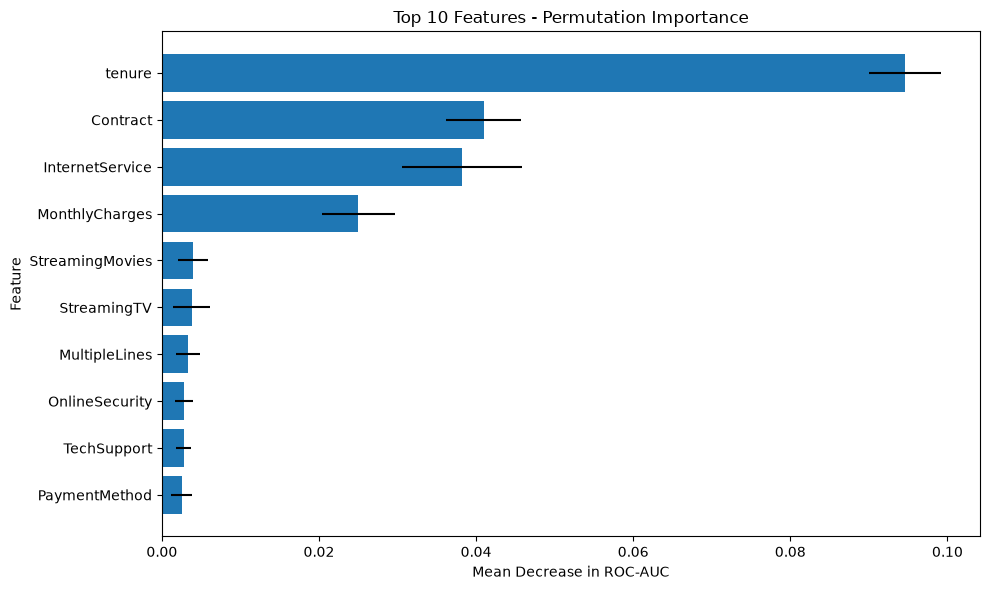

In [41]:
top_features = importance_df.head(10).sort_values(
    "Importance Mean", ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance Mean"],
    xerr=top_features["Importance Std"]
)

plt.xlabel("Mean Decrease in ROC-AUC")
plt.ylabel("Feature")
plt.title("Top 10 Features - Permutation Importance")
plt.tight_layout()
plt.show()

In [42]:
# Predict churn probability for each test customer
y_test_proba = final_lr_model.predict_proba(X_test)[:, 1]

# Create a customer-level results DataFrame
retention_df = X_test.copy()

retention_df["Actual_Churn"] = y_test
retention_df["Churn_Probability"] = y_test_proba

retention_df["Predicted_Churn"] = (
    retention_df["Churn_Probability"] >= best_threshold
).astype(int)

# Assign risk groups based on predicted churn probability
retention_df["Risk_Group"] = pd.cut(
    retention_df["Churn_Probability"],
    bins=[-np.inf, 0.20, 0.35, np.inf],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

retention_df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Churn_Probability,Predicted_Churn,Risk_Group
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20,0,0.042836,0,Low Risk
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,0,0.671798,1,High Risk
2235,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,...,No,One year,Yes,Credit card (automatic),78.35,3211.20,0,0.057531,0,Low Risk
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,...,No,Month-to-month,No,Electronic check,78.20,1468.75,0,0.332293,0,Medium Risk
3761,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,...,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35,0,0.027914,0,Low Risk


In [43]:
# Count customers in each risk group
risk_counts = retention_df["Risk_Group"].value_counts(sort=False)

# Calculate the percentage of customers in each group
risk_percentages = (
    retention_df["Risk_Group"]
    .value_counts(normalize=True, sort=False) * 100
)

# Combine counts and percentages into one table
risk_summary = pd.DataFrame({
    "Number of Customers": risk_counts,
    "Percentage (%)": risk_percentages
})

risk_summary.round(2)

,Number of Customers,Percentage (%)
Risk_Group,,
Low Risk,726,51.53
Medium Risk,210,14.90
High Risk,473,33.57


In [44]:
risk_performance = (
    retention_df.groupby("Risk_Group", observed=False)
    .agg(
        Number_of_Customers=("Actual_Churn", "size"),
        Actual_Churned=("Actual_Churn", "sum"),
        Actual_Churn_Rate=("Actual_Churn", "mean"),
        Average_Predicted_Risk=("Churn_Probability", "mean")
    )
)

risk_performance["Actual_Churn_Rate"] *= 100
risk_performance["Average_Predicted_Risk"] *= 100

risk_performance.round(2)

,Number_of_Customers,Actual_Churned,Actual_Churn_Rate,Average_Predicted_Risk
Risk_Group,,,,
Low Risk,726,50,6.89,6.49
Medium Risk,210,59,28.10,27.00
High Risk,473,265,56.03,57.95


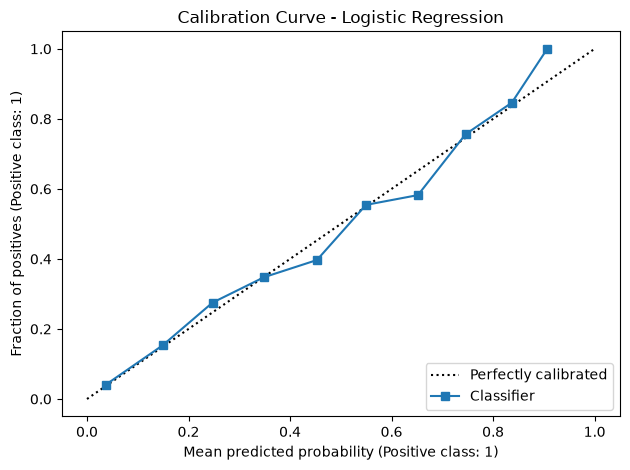

In [45]:
y_test_proba = final_lr_model.predict_proba(X_test)[:, 1]

CalibrationDisplay.from_predictions(
    y_test,
    y_test_proba,
    n_bins=10,
    strategy="uniform"
)

plt.title("Calibration Curve - Logistic Regression")
plt.tight_layout()
plt.show()

In [46]:
# Baseline: predict the same churn probability for every customer
baseline_probability = y_train.mean()

y_test_proba_baseline = np.full(
    shape=len(y_test),
    fill_value=baseline_probability
)

baseline_brier = brier_score_loss(
    y_test, y_test_proba_baseline
)

model_brier = brier_score_loss(
    y_test, y_test_proba
)

print("Baseline Brier Score:", round(baseline_brier, 4))
print("Logistic Regression Brier Score:", round(model_brier, 4))

Baseline Brier Score: 0.195
Logistic Regression Brier Score: 0.1364


In [47]:
import joblib

joblib.dump(
    {
        "model": final_lr_model,
        "threshold": best_threshold,
        "features": X_train.columns.tolist()
    },
    "customer_churn_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [48]:
saved_model = joblib.load("customer_churn_model.pkl")

loaded_model = saved_model["model"]
loaded_threshold = saved_model["threshold"]
loaded_features = saved_model["features"]

print("Threshold:", loaded_threshold)
print("Number of features:", len(loaded_features))
print("Model loaded successfully!")

Threshold: 0.35
Number of features: 19
Model loaded successfully!


In [49]:
# Select 5 customers from the test set
sample_customers = X_test.iloc[:5]

# Predictions before and after saving
predictions_before = final_lr_model.predict_proba(sample_customers)[:, 1]
predictions_after = loaded_model.predict_proba(sample_customers)[:, 1]

# Compare probabilities
comparison = pd.DataFrame({
    "Original Probability": predictions_before,
    "Loaded Probability": predictions_after
})

comparison["Difference"] = (
    comparison["Original Probability"] -
    comparison["Loaded Probability"]
).abs()

comparison["Predicted Churn"] = (
    comparison["Loaded Probability"] >= loaded_threshold
).astype(int)

comparison.round(6)

,Original Probability,Loaded Probability,Difference,Predicted Churn
0,0.042836,0.042836,0.0,0
1,0.671798,0.671798,0.0,1
2,0.057531,0.057531,0.0,0
3,0.332293,0.332293,0.0,0
4,0.027914,0.027914,0.0,0


## Business Recommendations

**Key findings**
- Month-to-month customers churn at 42.7%, versus 11.3% on one-year and 2.8% on two-year contracts.
- Fiber optic customers churn at 41.9% (DSL: 19.0%).
- Electronic check users churn at 45.3%; other payment methods sit between 15% and 19%.
- Churners leave early: median tenure is 10 months, versus 38 for retained customers.
- The High Risk group is 33.6% of customers but contains 265 of the 374 churners (71%), with an actual churn rate of 56%.

**Recommended actions**
1. **Contract upgrades:** offer a discount to move high-risk month-to-month customers to annual plans.
2. **Early-tenure onboarding:** run a retention program during the first 6 months, when risk is highest.
3. **Fiber optic review:** investigate service quality and pricing, since churn is more than double that of DSL.
4. **Automatic payments:** encourage a switch from electronic check to automatic payment methods.
5. **Targeted offers:** send retention offers only to customers with churn probability ≥ 0.35.
